In [1]:
!pip -q install pandas numpy matplotlib seaborn scikit-learn folium requests ipywidgets scipy

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import zipfile
from pathlib import Path

print("All libraries imported successfully!")


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Python314\python.exe -m pip install --upgrade pip


All libraries imported successfully!


In [2]:

from pathlib import Path
import os

# Main project directory
project_folder = Path.cwd()

# Project subfolders
data_folder = project_folder / "Data"
results_folder = project_folder / "Results"
website_folder = project_folder / "Website"

# Check the folders
print("PROJECT FOLDER:", project_folder)
print("DATA FOLDER:", data_folder)
print("RESULTS FOLDER:", results_folder)
print("WEBSITE FOLDER:", website_folder)

print("\nFolder verification:")
print("Data:", data_folder.exists())
print("Results:", results_folder.exists())
print("Website:", website_folder.exists())



PROJECT FOLDER: c:\SEM 5\PDS\PODS_Project
DATA FOLDER: c:\SEM 5\PDS\PODS_Project\Data
RESULTS FOLDER: c:\SEM 5\PDS\PODS_Project\Results
WEBSITE FOLDER: c:\SEM 5\PDS\PODS_Project\Website

Folder verification:
Data: True
Results: True
Website: True


In [3]:

import pandas as pd
from pathlib import Path

# Main project folder
project_folder = Path.cwd()

# Original collision dataset inside Data folder
file_path = (
    project_folder
    / "Data"
    / "dft-road-casualty-statistics-collision-last-5-years.csv"
)

# Load dataset
df = pd.read_csv(file_path, low_memory=False)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (513801, 44)


,collision_index,collision_year,collision_ref_no,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,collision_severity,number_of_vehicles,...,carriageway_hazards_historic,carriageway_hazards,urban_or_rural_area,did_police_officer_attend_scene_of_accident,trunk_road_flag,lsoa_of_accident_location,enhanced_severity_collision,collision_injury_based,collision_adjusted_severity_serious,collision_adjusted_severity_slight
0,202417H105824,2024,17H105824,448628.0,533968.0,-1.24700,54.69840,17,2,2,...,-1,0,1,1,2,E01012005,7,1,1.0,0.0
1,202517M115025,2025,17M115025,452379.0,519038.0,-1.19147,54.56387,17,2,2,...,-1,0,1,1,2,E01012090,6,1,1.0,0.0
2,202517L306225,2025,17L306225,459273.0,523811.0,-1.08390,54.60600,17,3,2,...,-1,0,1,1,2,E01032560,3,1,0.0,1.0
3,202417S104724,2024,17S104724,440460.0,517548.0,-1.37599,54.55157,17,3,2,...,-1,0,2,1,1,E01012269,3,1,0.0,1.0
4,202517S106525,2025,17S106525,444331.0,518776.0,-1.31596,54.56228,17,2,2,...,-1,0,1,1,2,E01035199,7,1,1.0,0.0


****STEP 2: DATA CLEANING****

---



In [4]:

# Create a copy of the original dataset
clean_df = df.copy()

# Remove duplicate collision records
clean_df = clean_df.drop_duplicates(
    subset=["collision_index"]
)

# Convert latitude and longitude to numbers
clean_df["latitude"] = pd.to_numeric(
    clean_df["latitude"], errors="coerce"
)

clean_df["longitude"] = pd.to_numeric(
    clean_df["longitude"], errors="coerce"
)

# Remove records without coordinates
clean_df = clean_df.dropna(
    subset=["latitude", "longitude"]
)

# Keep coordinates within Great Britain
clean_df = clean_df[
    clean_df["latitude"].between(49, 61) &
    clean_df["longitude"].between(-9, 3)
].copy()

# Convert date column
clean_df["date"] = pd.to_datetime(
    clean_df["date"],
    format="%d/%m/%Y",
    errors="coerce"
)

# Create severity labels
severity_map = {
    1: "Fatal",
    2: "Serious",
    3: "Slight"
}

clean_df["severity_label"] = (
    clean_df["collision_severity"].map(severity_map)
)

# Extract year and month
clean_df["year"] = clean_df["date"].dt.year
clean_df["month"] = clean_df["date"].dt.month

print("Data cleaning completed!")
print("Original records:", len(df))
print("Cleaned records:", len(clean_df))
print("Removed records:", len(df) - len(clean_df))

display(clean_df.head())


Data cleaning completed!
Original records: 513801
Cleaned records: 513748
Removed records: 53


,collision_index,collision_year,collision_ref_no,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,collision_severity,number_of_vehicles,...,did_police_officer_attend_scene_of_accident,trunk_road_flag,lsoa_of_accident_location,enhanced_severity_collision,collision_injury_based,collision_adjusted_severity_serious,collision_adjusted_severity_slight,severity_label,year,month
0,202417H105824,2024,17H105824,448628.0,533968.0,-1.24700,54.69840,17,2,2,...,1,2,E01012005,7,1,1.0,0.0,Serious,2024,10
1,202517M115025,2025,17M115025,452379.0,519038.0,-1.19147,54.56387,17,2,2,...,1,2,E01012090,6,1,1.0,0.0,Serious,2025,11
2,202517L306225,2025,17L306225,459273.0,523811.0,-1.08390,54.60600,17,3,2,...,1,2,E01032560,3,1,0.0,1.0,Slight,2025,6
3,202417S104724,2024,17S104724,440460.0,517548.0,-1.37599,54.55157,17,3,2,...,1,1,E01012269,3,1,0.0,1.0,Slight,2024,4
4,202517S106525,2025,17S106525,444331.0,518776.0,-1.31596,54.56228,17,2,2,...,1,2,E01035199,7,1,1.0,0.0,Serious,2025,5


#SAVING

In [ ]:

output_path = (
    "/content/drive/MyDrive/PODS_Project/"
    "cleaned_collision_data.csv"
)

clean_df.to_csv(output_path, index=False)

print("Cleaned dataset saved successfully!")


Cleaned dataset saved successfully!


In [5]:

print("Accidents by severity:")
print(clean_df["severity_label"].value_counts())

print("\nAccidents by year:")
print(clean_df["year"].value_counts().sort_index())


Accidents by severity:
severity_label
Slight     389399
Serious    116797
Fatal        7552
Name: count, dtype: int64

Accidents by year:
year
2021    101070
2022    105982
2023    104246
2024    100927
2025    101523
Name: count, dtype: int64


#**STEP 3-EDA ANALYSIS**

**1. Collisions by Severity**

This graph shows the distribution of road accidents based on severity levels: Slight, Serious, and Fatal. Most recorded collisions are slight, while fatal collisions are comparatively fewer.

**2. Collisions by Year**

This line graph illustrates the yearly accident trends from 2021 to 2025. It helps identify changes in accident frequency over time, with 2022 recording the highest number of collisions.

**3. Collisions by Speed Limit**

This bar graph represents the number of accidents recorded on roads with different speed limits. It helps identify which speed-limit categories have higher accident frequencies.

**4. Collisions by Month**

This graph displays the monthly distribution of road accidents across the five-year period. It helps identify seasonal patterns and months with higher accident frequencies.

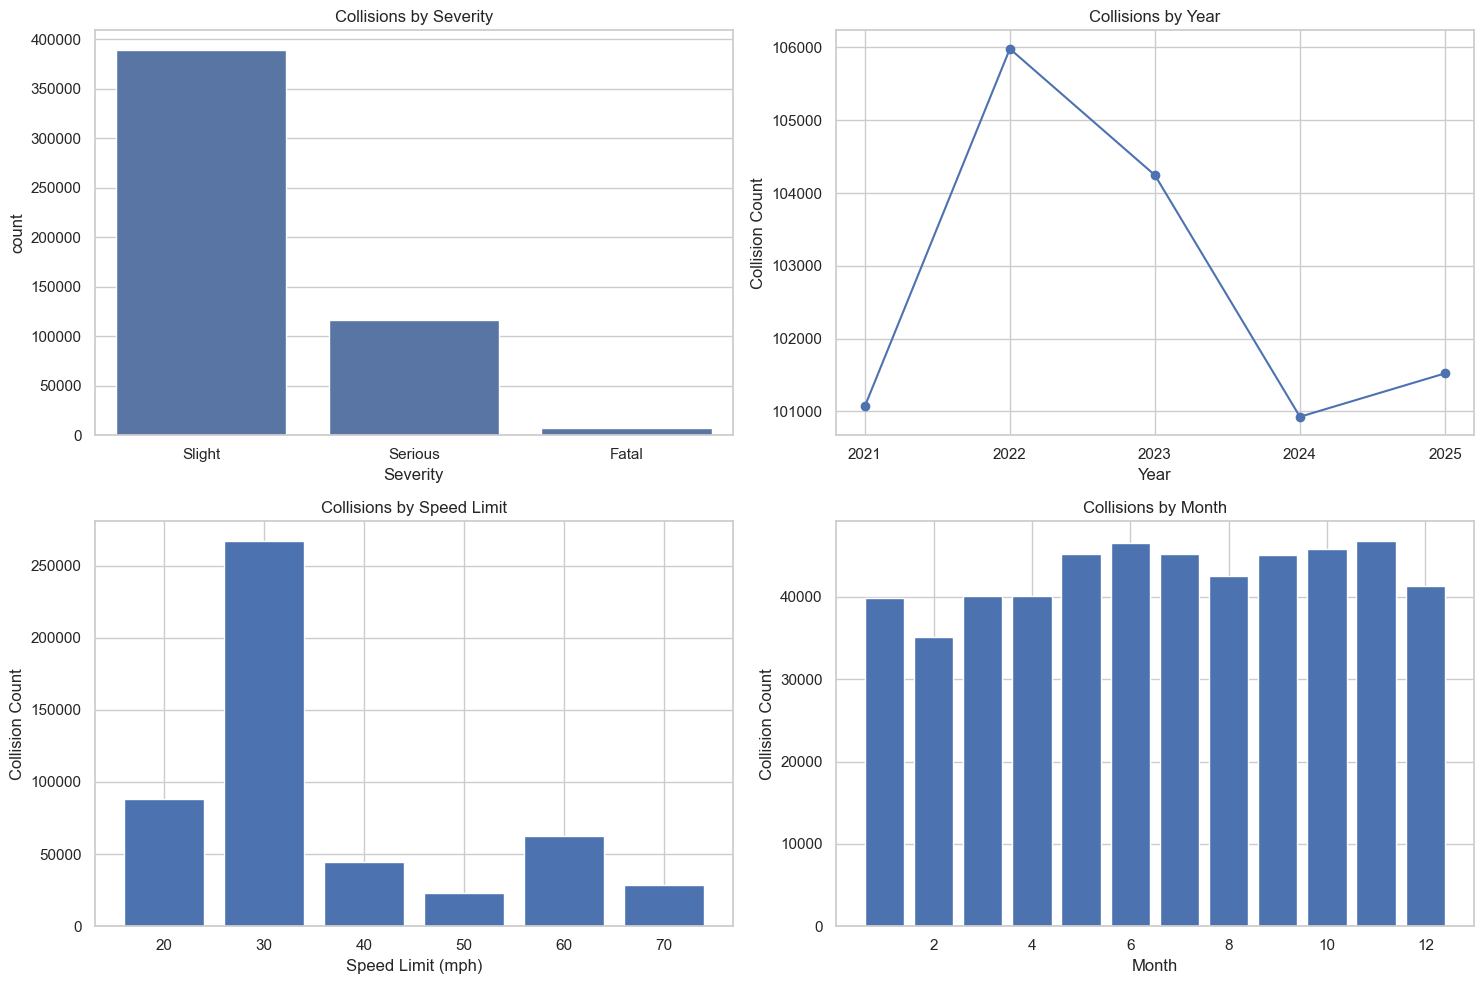

In [6]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Graph 1: Collision severity
order = ["Slight", "Serious", "Fatal"]
sns.countplot(
    data=clean_df,
    x="severity_label",
    order=order,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Collisions by Severity")
axes[0, 0].set_xlabel("Severity")

# Graph 2: Collisions by year
year_counts = clean_df["year"].value_counts().sort_index()
axes[0, 1].plot(
    year_counts.index,
    year_counts.values,
    marker="o"
)
axes[0, 1].set_title("Collisions by Year")
axes[0, 1].set_xlabel("Year")
axes[0, 1].set_ylabel("Collision Count")
axes[0, 1].set_xticks(year_counts.index)

# Graph 3: Collisions by speed limit
speed_counts = (
    clean_df.loc[
        clean_df["speed_limit"].isin([20, 30, 40, 50, 60, 70]),
        "speed_limit"
    ]
    .value_counts()
    .sort_index()
)
axes[1, 0].bar(
    speed_counts.index.astype(str),
    speed_counts.values
)
axes[1, 0].set_title("Collisions by Speed Limit")
axes[1, 0].set_xlabel("Speed Limit (mph)")
axes[1, 0].set_ylabel("Collision Count")

# Graph 4: Collisions by month
month_counts = clean_df["month"].value_counts().sort_index()
axes[1, 1].bar(
    month_counts.index,
    month_counts.values
)
axes[1, 1].set_title("Collisions by Month")
axes[1, 1].set_xlabel("Month")
axes[1, 1].set_ylabel("Collision Count")

plt.tight_layout()
plt.show()


In [ ]:

fig.savefig(
    "/content/drive/MyDrive/PODS_Project/EDA_Graphs.png",
    dpi=300,
    bbox_inches="tight"
)

print("EDA graphs saved successfully!")


EDA graphs saved successfully!


#**Step 4 – Accident Blackspot Detection:**
 **Identify accident-prone locations by grouping nearby collisions, counting their frequency and severity, and classifying blackspots into Maroon (Very High), Red (Medium), and Orange (Detected) categories for map visualization.**

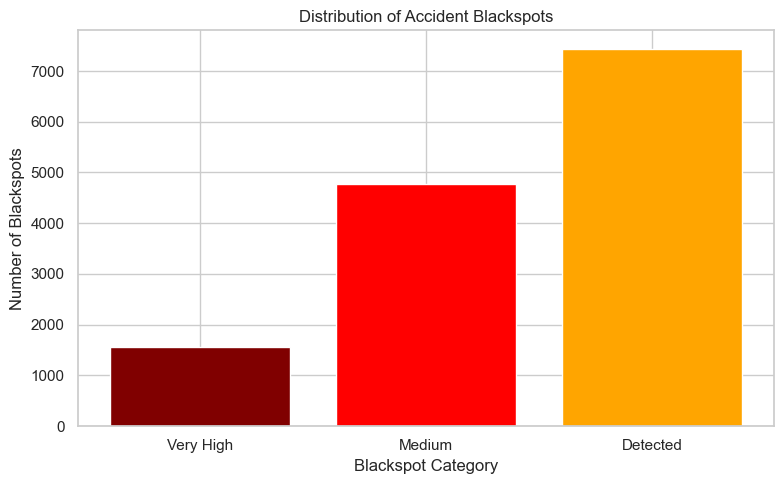

In [7]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. Round coordinates to group nearby collisions (~100m radius)
clean_df['lat_round'] = clean_df['latitude'].round(3)
clean_df['lon_round'] = clean_df['longitude'].round(3)

# 2. Define severity weights
severity_weights = {'Fatal': 5, 'Serious': 3, 'Slight': 1}
clean_df['severity_weight'] = clean_df['severity_label'].map(severity_weights).fillna(1)

# 3. Aggregate collisions by rounded locations
blackspots = clean_df.groupby(['lat_round', 'lon_round']).agg(
    collision_count=('collision_index', 'count'),
    total_severity_score=('severity_weight', 'sum')
).reset_index()

# 4. Filter for locations with at least 5 accidents to qualify as a blackspot
blackspots = blackspots[blackspots['collision_count'] >= 5].copy()

# 5. Classify blackspots into categories using severity score quantiles
if not blackspots.empty:
    high_threshold = blackspots['total_severity_score'].quantile(0.90)
    med_threshold = blackspots['total_severity_score'].quantile(0.60)

    def assign_risk_level(score):
        if score >= high_threshold:
            return "Very High"
        elif score >= med_threshold:
            return "Medium"
        else:
            return "Detected"

    blackspots['risk_level'] = blackspots['total_severity_score'].apply(assign_risk_level)
else:
    blackspots['risk_level'] = pd.Series(dtype='str')

# 6. Plot the distribution of accident blackspots
order = ["Very High", "Medium", "Detected"]
counts = (
    blackspots["risk_level"]
    .value_counts()
    .reindex(order, fill_value=0)
)

plt.figure(figsize=(8, 5))
plt.bar(
    counts.index,
    counts.values,
    color=["maroon", "red", "orange"]
)

plt.title("Distribution of Accident Blackspots")
plt.xlabel("Blackspot Category")
plt.ylabel("Number of Blackspots")

plt.tight_layout()
plt.show()

In [ ]:

# Rename rounded coordinates for map use
blackspots = blackspots.rename(columns={
    "lat_round": "latitude",
    "lon_round": "longitude"
})

# Assign pin colours
color_map = {
    "Very High": "maroon",
    "Medium": "red",
    "Detected": "orange"
}

blackspots["color"] = blackspots["risk_level"].map(color_map)

# Save to Google Drive
save_path = (
    "/content/drive/MyDrive/PODS_Project/"
    "blackspots.csv"
)

blackspots.to_csv(save_path, index=False)

print("Blackspot dataset saved successfully!")
print("Total blackspots:", len(blackspots))

print("\nBlackspots by category:")
print(blackspots["risk_level"].value_counts())

display(blackspots.head())


Blackspot dataset saved successfully!
Total blackspots: 13763

Blackspots by category:
risk_level
Detected     7429
Medium       4772
Very High    1562
Name: count, dtype: int64


,latitude,longitude,collision_count,total_severity_score,risk_level,color
257,50.118,-5.541,5,9,Detected,orange
330,50.126,-5.528,5,7,Detected,orange
337,50.127,-5.524,5,7,Detected,orange
489,50.151,-5.078,5,7,Detected,orange
750,50.188,-5.123,5,7,Detected,orange


#**Step 5-— Interactive Route Map**


Save the identified accident blackspots with their geographical coordinates, severity scores and colour-coded risk levels for interactive route visualization.


Step 5.1 — Load our saved blackspot dataset

In [18]:

%pip install pandas numpy matplotlib seaborn scikit-learn scipy folium requests ipywidgets ipykernel


import pandas as pd
import numpy as np
import folium
import requests
import ipywidgets as widgets

from pathlib import Path
from scipy.spatial import cKDTree
from IPython.display import display

# Local project folder
project_folder = Path.cwd()

# Load saved blackspot dataset
blackspots = pd.read_csv(
    project_folder / "Data" / "blackspots.csv"
)

print("Blackspots loaded successfully!")
print("Total blackspots:", len(blackspots))

display(blackspots.head())


   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.2 MB 2.2 MB/s eta 0:00:04
   ----- ---------------------------------- 1.0/8.2 MB 2.4 MB/s eta 0:00:03
   ----- ---------------------------------- 1.0/8.2 MB 2.4 MB/s eta 0:00:03
   ----- ---------------------------------- 1.0/8.2 MB 2.4 MB/s eta 0:00:03
   ------ --------------------------------- 1.3/8.2 MB 1.1 MB/s eta 0:00:07
   ------ --------------------------------- 1.3/8.2 MB 1.1 MB/s eta 0:00:07
   ------ --------------------------------- 1.3/8.2 MB 1.1 MB/s eta 0:00:07
   ------ --------------------------------- 1.3/8.2 MB 1.1 MB/s eta 0:00:07
   ------- -------------------------------- 1.6/8.2 MB 720.8 kB/s eta 0:00:10
   -------- ------------------------------- 1.8/8.2 MB 796.5 kB/s eta 0:00:09
   ----------- ---------------------------- 2.4/8.2 MB 937.5 kB/s eta 0:00:07
   -------------- ------------------------- 2.9/8.2 MB 1.1 MB/s eta 0:00:05
   ----------


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Blackspots loaded successfully!
Total blackspots: 13763


,latitude,longitude,collision_count,total_severity_score,risk_level,color
0,50.118,-5.541,5,9,Detected,orange
1,50.126,-5.528,5,7,Detected,orange
2,50.127,-5.524,5,7,Detected,orange
3,50.151,-5.078,5,7,Detected,orange
4,50.188,-5.123,5,7,Detected,orange


**Step 5.2 — Convert Locations into Coordinates and Calculate the Driving Route**

Convert user-entered UK locations into geographical coordinates and calculate the driving route between the starting point and destination using OpenStreetMap services.

In [19]:

import requests

# Convert location name into latitude and longitude
def get_coordinates(place):

    url = "https://nominatim.openstreetmap.org/search"

    response = requests.get(
        url,
        params={
            "q": place,
            "format": "json",
            "countrycodes": "gb",
            "limit": 1
        },
        headers={
            "User-Agent": "PODS-Blackspot-EducationalProject/1.0"
        },
        timeout=20
    )

    response.raise_for_status()
    data = response.json()

    if not data:
        raise ValueError("Location not found: " + place)

    latitude = float(data[0]["lat"])
    longitude = float(data[0]["lon"])

    return latitude, longitude


# Test location search
import time

start = get_coordinates("King's Cross Station, London")

time.sleep(1.1)

end = get_coordinates("Waterloo Station, London")




print("Starting coordinates:", start)
print("Destination coordinates:", end)


Starting coordinates: (51.5305975, -0.1229032)
Destination coordinates: (51.5028581, -0.1128074)


 Retrieve a road-based driving route between two UK locations using the OSRM routing service.

In [20]:

def get_driving_route(start, end):

    start_lat, start_lon = start
    end_lat, end_lon = end

    url = (
        "https://router.project-osrm.org/route/v1/driving/"
        f"{start_lon},{start_lat};{end_lon},{end_lat}"
    )

    response = requests.get(
        url,
        params={
            "overview": "full",
            "geometries": "geojson"
        },
        timeout=30
    )

    response.raise_for_status()
    data = response.json()

    if data.get("code") != "Ok" or not data.get("routes"):
        raise ValueError("No driving route found.")

    route = data["routes"][0]

    # Convert [longitude, latitude] to [latitude, longitude]
    route_points = [
        [lat, lon]
        for lon, lat in route["geometry"]["coordinates"]
    ]

    distance_km = route["distance"] / 1000

    return route_points, distance_km


# Test driving route
route_points, distance_km = get_driving_route(start, end)

print("Route calculated successfully!")
print("Distance:", round(distance_km, 2), "km")
print("Route coordinate points:", len(route_points))


Route calculated successfully!
Distance: 5.05 km
Route coordinate points: 400


**Step 5.3 — Identify Blackspots Along the Driving Route**


Identify historical accident blackspots within 100 metres of the selected driving route using geographical distance calculations and spatial nearest-neighbour searching.



In [21]:

import numpy as np
from scipy.spatial import cKDTree

def find_nearby_blackspots(route_points, max_distance=100):

    # Convert coordinates to a local metre-based projection
    earth_radius = 6371000

    reference_lat = np.radians(
        np.mean([point[0] for point in route_points])
    )

    def project(latitudes, longitudes):
        x = (
            np.radians(longitudes)
            * earth_radius
            * np.cos(reference_lat)
        )
        y = np.radians(latitudes) * earth_radius

        return np.column_stack((x, y))

    route_array = np.array(route_points)

    route_xy = project(
        route_array[:, 0],
        route_array[:, 1]
    )

    blackspot_xy = project(
        blackspots["latitude"].to_numpy(),
        blackspots["longitude"].to_numpy()
    )

    # Add points approximately every 20 metres
    dense_route = [route_xy[0]]

    for a, b in zip(route_xy[:-1], route_xy[1:]):
        segment_length = np.linalg.norm(b - a)

        steps = max(
            1,
            int(np.ceil(segment_length / 20))
        )

        for t in range(1, steps + 1):
            dense_route.append(
                a + (b - a) * t / steps
            )

    # Find nearest route point for each blackspot
    tree = cKDTree(np.array(dense_route))

    distances, _ = tree.query(blackspot_xy)

    # Select blackspots within the specified distance
    nearby = blackspots[
        distances <= max_distance
    ].copy()

    nearby["distance_to_route_m"] = (
        distances[distances <= max_distance]
    )

    return nearby


# Test using our calculated driving route
nearby_blackspots = find_nearby_blackspots(
    route_points,
    max_distance=100
)

print("Blackspots near route:", len(nearby_blackspots))

print("\nBlackspots by risk level:")
print(nearby_blackspots["risk_level"].value_counts())

display(nearby_blackspots.head())


Blackspots near route: 34

Blackspots by risk level:
risk_level
Very High    14
Detected     14
Medium        6
Name: count, dtype: int64


,latitude,longitude,collision_count,total_severity_score,risk_level,color,distance_to_route_m
4843,51.502,-0.110,8,12,Medium,red,7.328464
4872,51.503,-0.111,12,14,Medium,red,10.719496
4899,51.504,-0.113,8,10,Medium,red,45.044718
4900,51.504,-0.112,13,21,Very High,maroon,3.371643
4935,51.505,-0.114,12,16,Medium,red,28.362838


**Stage 5.4 — Interactive Route Visualization with Coloured Blackspot Pins**

Visualize the selected UK driving route on an interactive map and mark nearby historical accident blackspots using maroon, red and orange warning pins based on their risk classification.

In [24]:

import folium
from IPython.display import display


route_map = folium.Map(
    location=start,
    zoom_start=13,
    tiles=None
)

# Alternative street map tiles
folium.TileLayer(
    tiles="https://{s}.tile.openstreetmap.fr/hot/{z}/{x}/{y}.png",
    attr="© OpenStreetMap contributors, HOT",
    name="Humanitarian OpenStreetMap",
    max_zoom=19
).add_to(route_map)

# Draw the driving route
folium.PolyLine(
    locations=route_points,
    color="blue",
    weight=5,
    opacity=0.85,
    tooltip="Driving Route"
).add_to(route_map)

# Mark starting location
folium.Marker(
    location=start,
    popup="Starting Point: King's Cross Station",
    tooltip="START",
    icon=folium.Icon(
        color="green",
        icon="play"
    )
).add_to(route_map)

# Mark destination
folium.Marker(
    location=end,
    popup="Destination: Waterloo Station",
    tooltip="DESTINATION",
    icon=folium.Icon(
        color="blue",
        icon="flag"
    )
).add_to(route_map)

# Add coloured blackspot pins
for _, spot in nearby_blackspots.iterrows():

    risk = spot["risk_level"]

    if risk == "Very High":
        pin_color = "darkred"
    elif risk == "Medium":
        pin_color = "red"
    else:
        pin_color = "orange"

    popup_info = f"""
    <b>Accident Blackspot</b><br>
    Risk Level: {risk}<br>
    Historical Collisions: {int(spot['collision_count'])}<br>
    Severity Score: {spot['total_severity_score']}<br>
    Distance from Route:
    {spot['distance_to_route_m']:.1f} metres
    """

    folium.Marker(
        location=[
            spot["latitude"],
            spot["longitude"]
        ],
        popup=folium.Popup(
            popup_info,
            max_width=250
        ),
        tooltip=f"{risk} Blackspot",
        icon=folium.Icon(
            color=pin_color,
            icon="exclamation-sign"
        )
    ).add_to(route_map)

# Zoom to fit the entire route
route_map.fit_bounds(route_points)

# Display the interactive map
display(route_map)


saving

In [ ]:

route_map.save(
    "/content/drive/MyDrive/PODS_Project/route_blackspots_map.html"
)

print("Interactive blackspot map saved successfully!")


Interactive blackspot map saved successfully!


Stage 5.5 — Build the From/To Location Search Interface

Step 5.5.1 — Create the input boxes
Create an interactive interface that allows users to enter a starting location and destination for route-based accident blackspot analysi

In [25]:

import ipywidgets as widgets
from IPython.display import display

# Starting location input
start_input = widgets.Text(
    value="King's Cross Station, London",
    placeholder="Enter starting location",
    description="From:",
    style={"description_width": "80px"},
    layout=widgets.Layout(width="500px")
)

# Destination input
end_input = widgets.Text(
    value="Waterloo Station, London",
    placeholder="Enter destination",
    description="To:",
    style={"description_width": "80px"},
    layout=widgets.Layout(width="500px")
)

# Search button
search_button = widgets.Button(
    description="Find Route & Blackspots",
    button_style="primary",
    icon="search",
    layout=widgets.Layout(width="250px")
)

# Area for displaying results
output_area = widgets.Output()

# Display the interface
display(
    widgets.VBox([
        widgets.HTML(
            "<h3>Road Accident Blackspot Route Finder</h3>"
        ),
        start_input,
        end_input,
        search_button,
        output_area
    ])
)


In [ ]:

import ipywidgets as widgets
from IPython.display import display

# Test interactive widget support in VS Code
test_button = widgets.Button(
    description="Test Widgets",
    button_style="success"
)

display(test_button)

print("VS Code interactive widgets ready!")


Colab interactive widgets enabled!


Stage 5.5.2 — Connect the Search Button to Route Analysis
When a user clicks the button, our application will automatically:
1. Convert the two UK locations into coordinates.
2. Calculate a driving route.
3. Find historical accident blackspots within approximately 100 metres of the route.
4. Display the route and coloured blackspot pins on an interactive map.

Connect the route search button to geocoding, driving route calculation, nearby blackspot detection and interactive map visualization.

In [ ]:

from IPython.display import display, clear_output
import folium

def search_route_and_blackspots(button):

    with output_area:
        clear_output(wait=True)

        # Read user-entered locations
        from_place = start_input.value.strip()
        to_place = end_input.value.strip()

        if not from_place or not to_place:
            print("Please enter both starting and destination locations.")
            return

        print("Searching for route and nearby blackspots...")

        try:
            # Convert place names into coordinates
            new_start = get_coordinates(from_place)
            new_end = get_coordinates(to_place)

            # Calculate the driving route
            new_route_points, new_distance_km = get_driving_route(
                new_start,
                new_end
            )

            # Identify nearby historical blackspots
            new_nearby = find_nearby_blackspots(
                new_route_points,
                max_distance=100
            )

            # Show route information
            clear_output(wait=True)

            print("Route calculated successfully!")
            print(f"From: {from_place}")
            print(f"To: {to_place}")
            print(f"Distance: {new_distance_km:.2f} km")
            print(f"Nearby blackspots: {len(new_nearby)}")

            print("\nBlackspots by risk level:")
            print(new_nearby["risk_level"].value_counts())

            # Create the interactive map
            new_map = folium.Map(
                location=new_start,
                zoom_start=13,
                tiles=None
            )

            # Use the working map tile provider
            folium.TileLayer(
                tiles="https://{s}.tile.openstreetmap.fr/hot/{z}/{x}/{y}.png",
                attr="© OpenStreetMap contributors, HOT",
                name="Humanitarian OpenStreetMap",
                max_zoom=19
            ).add_to(new_map)

            # Draw the driving route
            folium.PolyLine(
                locations=new_route_points,
                color="blue",
                weight=5,
                opacity=0.85,
                tooltip="Driving Route"
            ).add_to(new_map)

            # Starting point
            folium.Marker(
                location=new_start,
                popup=f"Start: {from_place}",
                tooltip="START",
                icon=folium.Icon(
                    color="green",
                    icon="play"
                )
            ).add_to(new_map)

            # Destination
            folium.Marker(
                location=new_end,
                popup=f"Destination: {to_place}",
                tooltip="DESTINATION",
                icon=folium.Icon(
                    color="blue",
                    icon="flag"
                )
            ).add_to(new_map)

            # Add nearby blackspot markers
            for _, spot in new_nearby.iterrows():

                risk = spot["risk_level"]

                if risk == "Very High":
                    pin_color = "darkred"
                elif risk == "Medium":
                    pin_color = "red"
                else:
                    pin_color = "orange"

                popup_info = f"""
                <b>Historical Accident Blackspot</b><br>
                Risk Level: {risk}<br>
                Collisions: {int(spot['collision_count'])}<br>
                Severity Score: {spot['total_severity_score']}<br>
                Distance from Route:
                {spot['distance_to_route_m']:.1f} metres
                """

                folium.Marker(
                    location=[
                        spot["latitude"],
                        spot["longitude"]
                    ],
                    popup=folium.Popup(
                        popup_info,
                        max_width=250
                    ),
                    tooltip=f"{risk} Blackspot",
                    icon=folium.Icon(
                        color=pin_color,
                        icon="exclamation-sign"
                    )
                ).add_to(new_map)

            # Fit map to the calculated route
            new_map.fit_bounds(new_route_points)

            # Display map
            display(new_map)

            # Save latest searched route
            new_map.save(
                "/content/drive/MyDrive/PODS_Project/latest_searched_route.html"
            )

            print("Map saved to Google Drive successfully!")

        except Exception as error:
            print("Unable to complete the route search.")
            print("Error:", error)


# Connect the button to the function
search_button.on_click(search_route_and_blackspots)

print("Search button activated successfully!")


Search button activated successfully!


Step 5.6.3 — Fix the Search Button
Create a fresh interactive route-search interface and connect its button to the existing route analysis and blackspot visualization function.

In [ ]:

import ipywidgets as widgets
from IPython.display import display

# Create a fresh search button
search_button = widgets.Button(
    description="Find Route & Blackspots",
    button_style="primary",
    icon="search",
    layout=widgets.Layout(width="250px")
)

# Create a fresh output area
output_area = widgets.Output()

# Connect the new button to our existing search function
search_button.on_click(search_route_and_blackspots)

# Display the final interface
display(
    widgets.VBox([
        widgets.HTML(
            "<h3>Road Accident Blackspot Route Finder</h3>"
        ),
        start_input,
        end_input,
        search_button,
        output_area
    ])
)

print("Final interactive interface ready!")


Final interactive interface ready!


#Stage 6 — Predicting Future Accident Blackspots
Step 6.1 — Split the Dataset into Training and Testing Data
Split the cleaned UK road accident dataset into historical training data from 2021–2024 and testing data from 2025 for time-based blackspot prediction evaluation.

In [ ]:

import pandas as pd

# Reload the original cleaned dataset
clean_df = pd.read_csv(
    "/content/drive/MyDrive/PODS_Project/cleaned_collision_data.csv",
    low_memory=False
)

# Parse dates with support for mixed formats
clean_df["date"] = pd.to_datetime(
    clean_df["date"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

# Extract collision year
clean_df["year"] = clean_df["date"].dt.year

# Check date parsing
print("Total dataset records:", len(clean_df))
print("Dates not parsed:", clean_df["date"].isna().sum())

# Create training and testing datasets
train_df = clean_df[
    clean_df["year"].between(2021, 2024)
].copy()

test_df = clean_df[
    clean_df["year"] == 2025
].copy()

print("\nTraining records (2021-2024):", len(train_df))
print("Testing records (2025):", len(test_df))
print("Total training + testing:", len(train_df) + len(test_df))

print("\nRecords by year:")
print(clean_df["year"].value_counts().sort_index())


Total dataset records: 513748
Dates not parsed: 0

Training records (2021-2024): 412225
Testing records (2025): 101523
Total training + testing: 513748

Records by year:
year
2021    101070
2022    105982
2023    104246
2024    100927
2025    101523
Name: count, dtype: int64


Stage 6.2 — Build Training-Only Accident Blackspots
.
Calculate severity-weighted historical blackspot scores using the cleaned accident severity labels from the 2021–2024 training dataset.

In [ ]:

# Create a separate copy of training data
train_blackspot_df = train_df.copy()

# Round coordinates to group nearby collisions
train_blackspot_df["lat_round"] = (
    train_blackspot_df["latitude"].round(3)
)

train_blackspot_df["lon_round"] = (
    train_blackspot_df["longitude"].round(3)
)



# Assign severity weights using the cleaned labels
severity_weights = {
    "Fatal": 5,
    "Serious": 3,
    "Slight": 1
}

train_blackspot_df["severity_weight"] = (
    train_blackspot_df["severity_label"]
    .map(severity_weights)
)

# Verify severity weights
print("Severity weights:")
print(
    train_blackspot_df[
        ["severity_label", "severity_weight"]
    ].drop_duplicates()
)

print(
    "Missing severity weights:",
    train_blackspot_df["severity_weight"].isna().sum()
)

# Group historical collisions by location
train_blackspots = (
    train_blackspot_df
    .groupby(["lat_round", "lon_round"])
    .agg(
        collision_count=("collision_index", "count"),
        total_severity_score=("severity_weight", "sum")
    )
    .reset_index()
)

# Retain locations with at least 5 historical collisions
train_blackspots = train_blackspots[
    train_blackspots["collision_count"] >= 5
].copy()

# Calculate thresholds using training data only
high_threshold = (
    train_blackspots["total_severity_score"].quantile(0.90)
)

medium_threshold = (
    train_blackspots["total_severity_score"].quantile(0.60)
)

# Assign risk classifications
def classify_training_risk(score):
    if score >= high_threshold:
        return "Very High"
    elif score >= medium_threshold:
        return "Medium"
    else:
        return "Detected"

train_blackspots["risk_level"] = (
    train_blackspots["total_severity_score"]
    .apply(classify_training_risk)
)

# Rename coordinates
train_blackspots = train_blackspots.rename(
    columns={
        "lat_round": "latitude",
        "lon_round": "longitude"
    }
)

# Display results
print("Training-only blackspots:", len(train_blackspots))

print("\nRisk classification counts:")
print(train_blackspots["risk_level"].value_counts())

display(train_blackspots.head())


Severity weights:
    severity_label  severity_weight
0          Serious                3
3           Slight                1
158          Fatal                5
Missing severity weights: 0
Training-only blackspots: 9639

Risk classification counts:
risk_level
Detected     5605
Medium       2947
Very High    1087
Name: count, dtype: int64


,latitude,longitude,collision_count,total_severity_score,risk_level
215,50.118,-5.541,5,9,Detected
405,50.151,-5.078,5,7,Detected
685,50.197,-5.398,6,8,Detected
758,50.211,-5.481,6,10,Medium
992,50.238,-5.238,5,7,Detected


Stage 6.3 — Evaluate Predictions Using 2025 Collision Data
Evaluate historical blackspot predictions by measuring the percentage of 2025 collisions occurring within 100 metres of blackspots identified from 2021–2024 data.

In [ ]:

import numpy as np
from scipy.spatial import cKDTree

# Extract coordinates of training-only blackspots
predicted_coords = train_blackspots[
    ["latitude", "longitude"]
].to_numpy()

# Extract actual 2025 collision coordinates
actual_coords = test_df[
    ["latitude", "longitude"]
].to_numpy()

# Convert coordinates approximately into metres
earth_radius = 6371000

reference_lat = np.radians(
    np.mean(actual_coords[:, 0])
)

def coordinates_to_metres(coords):
    x = (
        np.radians(coords[:, 1])
        * earth_radius
        * np.cos(reference_lat)
    )

    y = np.radians(coords[:, 0]) * earth_radius

    return np.column_stack((x, y))

predicted_xy = coordinates_to_metres(predicted_coords)
actual_xy = coordinates_to_metres(actual_coords)

# Find nearest historical blackspot for each 2025 collision
tree = cKDTree(predicted_xy)

distances, nearest_indices = tree.query(actual_xy)

# Check whether each collision is within 100 metres
within_100m = distances <= 100

# Calculate collision coverage
covered_collisions = int(within_100m.sum())
total_collisions = len(test_df)

coverage_percentage = (
    covered_collisions / total_collisions
) * 100

print("2025 collisions evaluated:", total_collisions)
print("Predicted blackspots:", len(train_blackspots))
print("2025 collisions within 100m:", covered_collisions)
print(
    "Historical blackspot coverage:",
    f"{coverage_percentage:.2f}%"
)


2025 collisions evaluated: 101523
Predicted blackspots: 9639
2025 collisions within 100m: 18471
Historical blackspot coverage: 18.19%


Stage 6.4 — Evaluate Different Distance Thresholds
Compare historical blackspot prediction coverage at different distance thresholds to evaluate how proximity affects the detection of 2025 collision locations.

,Distance (metres),2025 Collisions Covered,Coverage (%)
0,50,11710,11.53
1,100,18471,18.19
2,150,22397,22.06
3,200,25734,25.35
4,300,31639,31.16


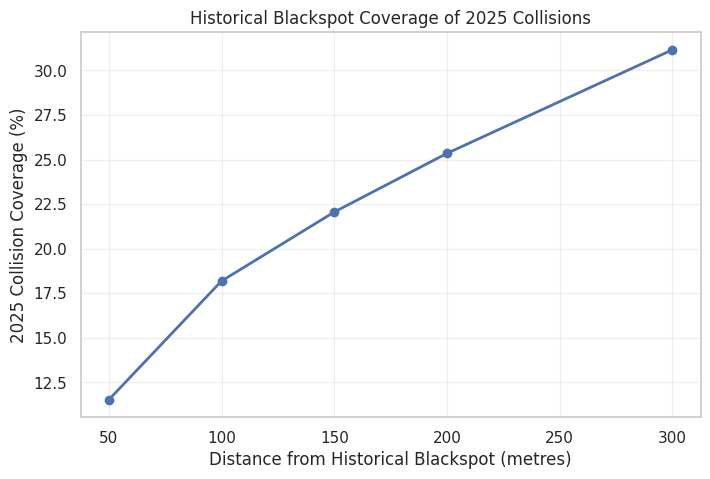

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Distances were calculated in Stage 6.3
distance_thresholds = [50, 100, 150, 200, 300]

results = []

for threshold in distance_thresholds:

    covered = int((distances <= threshold).sum())

    coverage = (
        covered / len(test_df)
    ) * 100

    results.append({
        "Distance (metres)": threshold,
        "2025 Collisions Covered": covered,
        "Coverage (%)": round(coverage, 2)
    })

# Create evaluation results table
evaluation_df = pd.DataFrame(results)

display(evaluation_df)

# Plot coverage by distance threshold
plt.figure(figsize=(8, 5))

plt.plot(
    evaluation_df["Distance (metres)"],
    evaluation_df["Coverage (%)"],
    marker="o",
    linewidth=2
)

plt.title("Historical Blackspot Coverage of 2025 Collisions")
plt.xlabel("Distance from Historical Blackspot (metres)")
plt.ylabel("2025 Collision Coverage (%)")
plt.grid(alpha=0.3)

plt.show()


Stage 6.5 — Compare Against a Random-Location Baseline
Compare historical blackspot prediction coverage against randomly selected training-period collision locations to evaluate whether the blackspot method performs better than a simple baseline.

In [ ]:

import numpy as np
import pandas as pd
from scipy.spatial import cKDTree

# Create a reproducible random generator
rng = np.random.default_rng(42)

# Use unique locations from training data only
random_candidates = (
    train_df[["latitude", "longitude"]]
    .round(3)
    .drop_duplicates()
    .to_numpy()
)

# Use the same number of locations as our blackspot model
number_of_locations = len(train_blackspots)

# Repeat the random comparison 20 times
random_coverages = []

for repeat in range(20):

    selected_indices = rng.choice(
        len(random_candidates),
        size=number_of_locations,
        replace=False
    )

    random_coords = random_candidates[selected_indices]

    # Use the same coordinate conversion as Stage 6.3
    random_xy = coordinates_to_metres(random_coords)

    random_tree = cKDTree(random_xy)

    random_distances, _ = random_tree.query(actual_xy)

    random_coverage = (
        (random_distances <= 100).sum()
        / len(test_df)
    ) * 100

    random_coverages.append(random_coverage)

# Compare results
historical_coverage = coverage_percentage
random_mean = np.mean(random_coverages)
random_std = np.std(random_coverages)

print("Historical blackspot coverage:",
      f"{historical_coverage:.2f}%")

print("Random baseline average coverage:",
      f"{random_mean:.2f}%")

print("Random baseline standard deviation:",
      f"{random_std:.2f}%")

print("Difference:",
      f"{historical_coverage - random_mean:.2f} percentage points")


Historical blackspot coverage: 18.19%
Random baseline average coverage: 4.91%
Random baseline standard deviation: 0.12%
Difference: 13.28 percentage points


Stage 6.6 — Save the Prediction Evaluation Results

In [ ]:

import pandas as pd

# Save training-only predicted blackspots
train_blackspots.to_csv(
    "/content/drive/MyDrive/PODS_Project/predicted_blackspots.csv",
    index=False
)

# Create summary of prediction evaluation
prediction_summary = pd.DataFrame({
    "Metric": [
        "Training Records (2021-2024)",
        "Testing Records (2025)",
        "Predicted Blackspots",
        "2025 Collisions Within 100m",
        "Historical Blackspot Coverage (%)",
        "Random Baseline Coverage (%)",
        "Coverage Improvement (Percentage Points)"
    ],
    "Value": [
        len(train_df),
        len(test_df),
        len(train_blackspots),
        covered_collisions,
        round(historical_coverage, 2),
        round(random_mean, 2),
        round(historical_coverage - random_mean, 2)
    ]
})

prediction_summary.to_csv(
    "/content/drive/MyDrive/PODS_Project/prediction_evaluation_summary.csv",
    index=False
)

# Save distance-threshold evaluation
evaluation_df.to_csv(
    "/content/drive/MyDrive/PODS_Project/distance_threshold_evaluation.csv",
    index=False
)

print("Prediction evaluation files saved successfully!")

display(prediction_summary)


Prediction evaluation files saved successfully!


,Metric,Value
0,Training Records (2021-2024),412225.00
1,Testing Records (2025),101523.00
2,Predicted Blackspots,9639.00
3,2025 Collisions Within 100m,18471.00
4,Historical Blackspot Coverage (%),18.19
5,Random Baseline Coverage (%),4.91
6,Coverage Improvement (Percentage Points),13.28


## Stage 7 — Project Conclusion

### Conclusion

The project **Road Accident Blackspot Prediction and Route-Based Visualization Using Interactive Maps** successfully analysed UK road collision data from 2021 to 2025 to identify historical accident-prone locations and visualize them along driving routes.

The dataset contained **513,748 cleaned collision records**. Accident blackspots were identified by grouping nearby collision locations and assigning severity-based weights to fatal, serious and slight collisions.

An interactive route-search application was developed using **Folium, OpenStreetMap-based mapping, Nominatim geocoding and OSRM routing**. Users can enter a starting point and destination, calculate a driving route and view nearby historical accident blackspots using colour-coded markers.

For prediction evaluation, **412,225 collisions from 2021–2024** were used to identify **9,639 historical blackspots**, while **101,523 collisions from 2025** were reserved for testing.

The historical blackspot method covered **18.19% of 2025 collisions within approximately 100 metres**, compared with **4.91% coverage** for a random historical-location baseline. This represents an improvement of **13.28 percentage points** in collision coverage.

These results suggest that historical collision concentrations provide useful information for identifying locations where future collisions may occur. However, the method is a historical spatial-risk prediction baseline rather than a trained machine-learning classifier. Its coverage is not equivalent to prediction accuracy, and the evaluation does not measure false-positive road locations.

Overall, the project demonstrates how data science, geographical analysis and interactive mapping can be combined to support road-safety awareness and the exploration of accident-prone routes.

### Future Enhancements

- Develop machine-learning models using road conditions, weather, lighting and traffic-related features.
- Evaluate precision, recall and geographical area coverage in addition to collision coverage.
- Introduce alternative-route comparisons to help users explore routes with fewer historical blackspots.
- Improve spatial accuracy using road-network segments instead of rounded coordinate grids.